# LabPicsV1

> Laboratory bench images with vessels and materials (Simple vs Complex difficulty; Train/Test splits).

**GT available:**
- Instance segmentation masks (`Instance/*.png`)
- Semantic segmentation masks by material/category (`Semantic/*`, available where provided)
- Material-category metadata per instance via `InstCategory.json` (Simple splits; includes multi-phase material/vessel flags)

In [14]:
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import matplotlib.patches as patches
from collections import Counter

# Set up paths
data_root = Path('../data/LabPicsV1')
simple_train_root = data_root / 'Simple' / 'Train'
simple_test_root = data_root / 'Simple' / 'Test'
complex_train_root = data_root / 'Complex' / 'Train'
complex_test_root = data_root / 'Complex' / 'Test'

print("Dataset paths configured successfully!")

Dataset paths configured successfully!


## Helper Functions

In [15]:
def load_annotation(root_path):
    """Load InstCategory.json from given root path. Returns empty dict if file doesn't exist."""
    annotation_file = root_path / 'InstCategory.json'
    if annotation_file.exists():
        with open(annotation_file, 'r') as f:
            return json.load(f)
    else:
        print(f"Warning: InstCategory.json not found in {root_path}")
        return {}

def get_image_names(root_path, limit=None):
    """Get list of image names from Image folder."""
    image_folder = root_path / 'Image'
    image_files = sorted([f.stem for f in image_folder.glob('*.jpg')])
    if limit:
        return image_files[:limit]
    return image_files

def load_rgb_image(root_path, image_name):
    """Load RGB image."""
    image_path = root_path / 'Image' / f'{image_name}.jpg'
    return np.array(Image.open(image_path))

def load_instance_mask(root_path, image_name):
    """Load instance segmentation mask."""
    mask_path = root_path / 'Instance' / f'{image_name}.png'
    img = Image.open(mask_path)
    # Convert to grayscale if color image
    if img.mode in ('RGB', 'RGBA', 'P'):
        img = img.convert('L')
    return np.array(img)

def create_instance_colormap(instance_mask):
    """Create a colorful visualization of instance mask."""
    unique_instances = np.unique(instance_mask)
    h, w = instance_mask.shape
    colored_mask = np.zeros((h, w, 3), dtype=np.uint8)
    
    cmap = plt.colormaps['tab20']
    for idx, inst_id in enumerate(unique_instances):
        if inst_id == 0:
            continue
        color = cmap(idx % 20)
        r = int(color[0] * 255)
        g = int(color[1] * 255)
        b = int(color[2] * 255)
        mask_bool = instance_mask == inst_id
        colored_mask[mask_bool, 0] = r
        colored_mask[mask_bool, 1] = g
        colored_mask[mask_bool, 2] = b
    
    return colored_mask

def overlay_mask_on_image(image, mask, alpha=0.5):
    """Overlay colored mask on image."""
    return (image * (1 - alpha) + mask * alpha).astype(np.uint8)

def visualize_sample(root_path, image_name, annotations, title_prefix=""):
    """Visualize a single sample with image, instance mask, and annotations."""
    rgb_image = load_rgb_image(root_path, image_name)
    instance_mask = load_instance_mask(root_path, image_name)
    colored_mask = create_instance_colormap(instance_mask)
    overlay = overlay_mask_on_image(rgb_image, colored_mask, alpha=0.4)
    
    anno = annotations.get(image_name, {})
    material_cats = anno.get('MaterialCats', {})
    multi_phase_materials = anno.get('MultiPhaseMaterial', [])
    multi_phase_vessels = anno.get('MultiPhaseVessels', [])
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(rgb_image)
    axes[0].set_title(f'{title_prefix} - RGB Image', fontsize=12, fontweight='bold')
    axes[0].axis('off')
    
    axes[1].imshow(instance_mask, cmap='tab20')
    axes[1].set_title(f'{title_prefix} - Instance Mask', fontsize=12, fontweight='bold')
    axes[1].axis('off')
    
    axes[2].imshow(overlay)
    axes[2].set_title(f'{title_prefix} - Overlay', fontsize=12, fontweight='bold')
    axes[2].axis('off')
    plt.tight_layout()
    
    print(f"\n{'='*80}")
    print(f"{title_prefix}")
    print(f"Image: {image_name}")
    print(f"{'='*80}")
    print(f"Number of instances: {len(np.unique(instance_mask)) - 1}")
    print(f"\nMaterial Categories by Instance ID:")
    for inst_id, materials in material_cats.items():
        print(f"  Instance {inst_id}: {', '.join(materials)}")
    if multi_phase_materials:
        print(f"\nMulti-phase material instances: {multi_phase_materials}")
    if multi_phase_vessels:
        print(f"Multi-phase vessel instances: {multi_phase_vessels}")
    plt.show()
    return rgb_image, instance_mask, anno

## Dataset Overview

This section provides statistics about the dataset including sample counts, material categories, and distribution across splits.

In [16]:
def get_dataset_statistics(split_roots):
    """Get statistics for each split. Skips splits without annotation files."""
    stats = {}
    for name, root in split_roots.items():
        annotation_file = root / 'InstCategory.json'
        if not annotation_file.exists():
            print(f"Skipping {name} - InstCategory.json not found")
            continue
        image_names = get_image_names(root)
        annotations = load_annotation(root)
        material_counter = Counter()
        multi_phase_count = 0
        instance_counts = []
        for img_name in image_names:
            anno = annotations.get(img_name, {})
            material_cats = anno.get('MaterialCats', {})
            for materials in material_cats.values():
                for mat in materials:
                    material_counter[mat] += 1
            if anno.get('MultiPhaseMaterial'):
                multi_phase_count += 1
            instance_counts.append(len(material_cats))
        if instance_counts:
            stats[name] = {
                'num_images': len(image_names),
                'num_instances_total': sum(instance_counts),
                'avg_instances': np.mean(instance_counts),
                'max_instances': max(instance_counts),
                'min_instances': min(instance_counts),
                'material_distribution': dict(material_counter),
                'multi_phase_count': multi_phase_count
            }
    return stats

split_roots = {
    'Simple-Train': simple_train_root,
    'Simple-Test': simple_test_root,
    'Complex-Train': complex_train_root,
    'Complex-Test': complex_test_root
}
stats = get_dataset_statistics(split_roots)

if stats:
    print("="*80)
    print("LabPicsV1 Dataset Statistics")
    print("="*80)
    for split_name, split_stats in stats.items():
        print(f"\n{split_name}:")
        print(f"  Number of images: {split_stats['num_images']}")
        print(f"  Total instances: {split_stats['num_instances_total']}")
        print(f"  Average instances per image: {split_stats['avg_instances']:.2f}")
        print(f"  Instance range: [{split_stats['min_instances']}, {split_stats['max_instances']}]")
        print(f"  Images with multi-phase materials: {split_stats['multi_phase_count']}")
    total_images = sum(s['num_images'] for s in stats.values())
    print(f"\nTotal images in dataset: {total_images}")
else:
    print("ERROR: No datasets with annotations found!")

Skipping Complex-Train - InstCategory.json not found
Skipping Complex-Test - InstCategory.json not found
LabPicsV1 Dataset Statistics

Simple-Train:
  Number of images: 1691
  Total instances: 3362
  Average instances per image: 1.99
  Instance range: [0, 25]
  Images with multi-phase materials: 676

Simple-Test:
  Number of images: 497
  Total instances: 817
  Average instances per image: 1.64
  Instance range: [1, 6]
  Images with multi-phase materials: 195

Total images in dataset: 2188


### Material Distribution Across Dataset

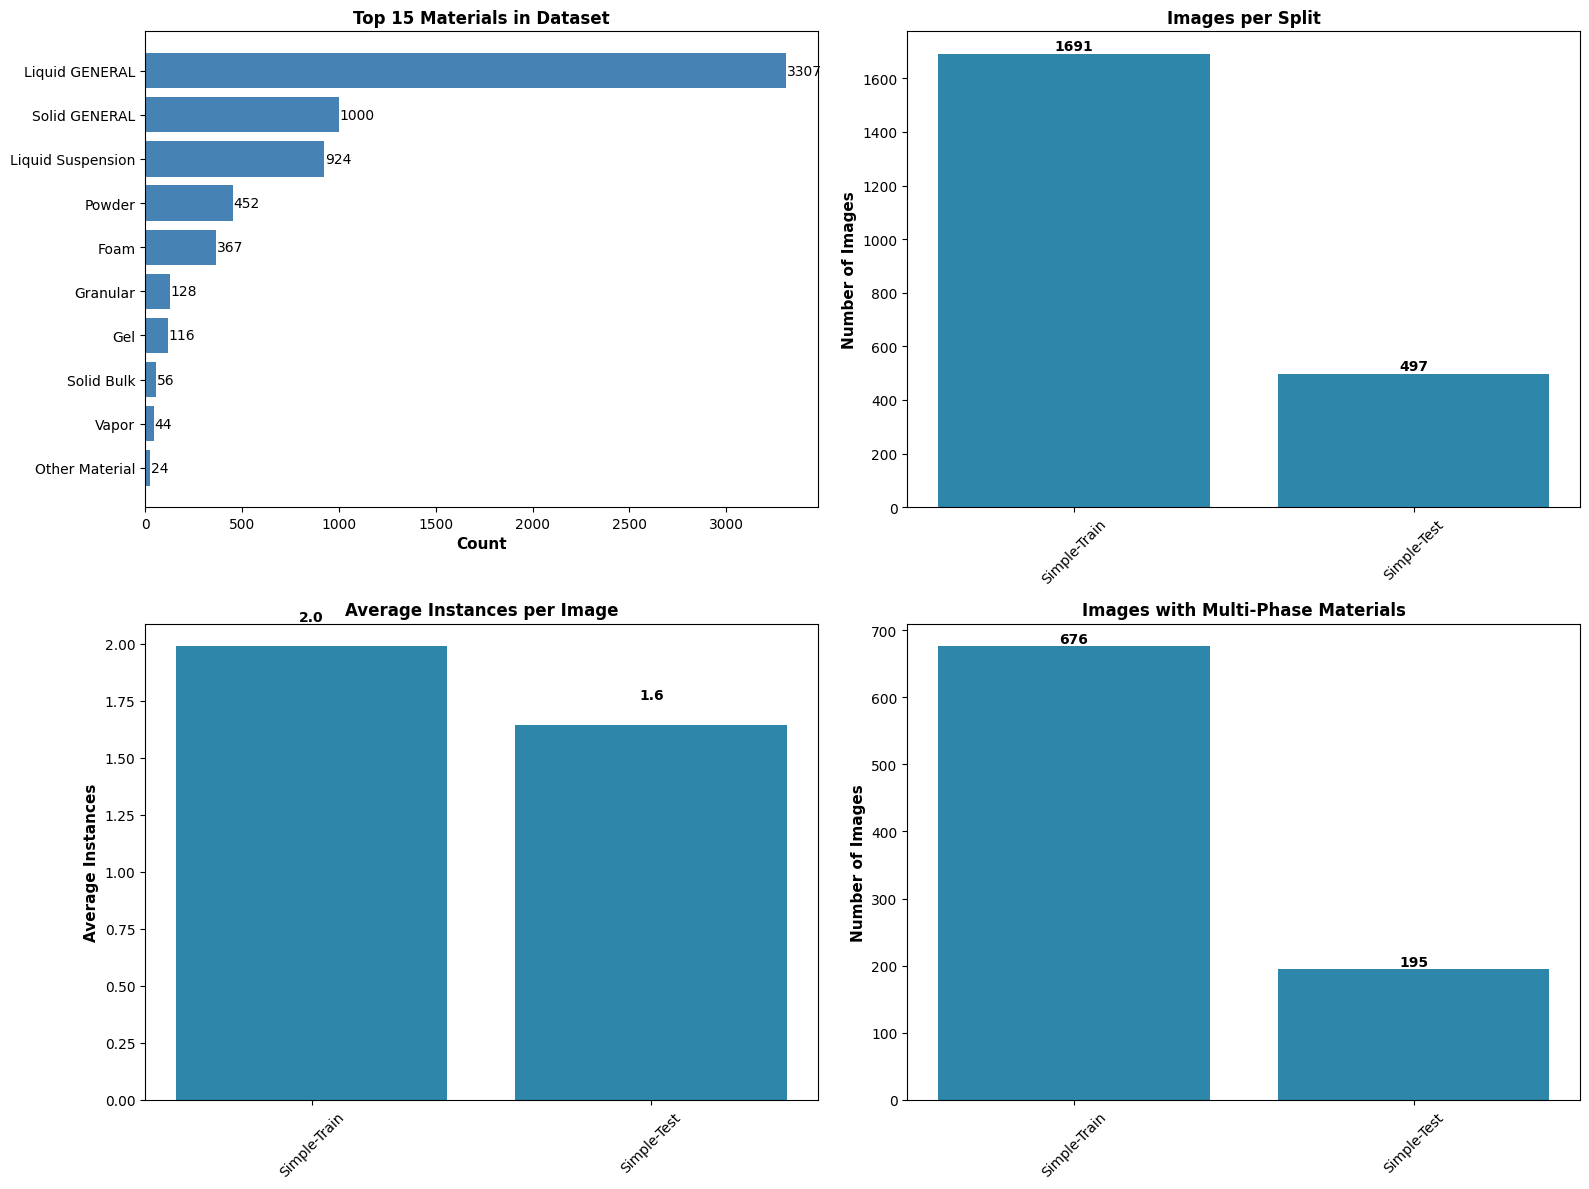

In [17]:
all_materials = Counter()
for split_stats in stats.values():
    for material, count in split_stats['material_distribution'].items():
        all_materials[material] += count

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
ax = axes[0, 0]
materials, counts = zip(*all_materials.most_common(15))
ax.barh(range(len(materials)), counts, color='steelblue')
ax.set_yticks(range(len(materials)))
ax.set_yticklabels(materials)
ax.set_xlabel('Count', fontsize=11, fontweight='bold')
ax.set_title('Top 15 Materials in Dataset', fontsize=12, fontweight='bold')
ax.invert_yaxis()
for i, (mat, count) in enumerate(zip(materials, counts)):
    ax.text(count + 5, i, str(count), va='center', fontsize=10)

ax = axes[0, 1]
split_names = list(stats.keys())
image_counts = [stats[name]['num_images'] for name in split_names]
colors = ['#2E86AB', '#2E86AB', '#A23B72', '#A23B72'][:len(split_names)]
bars = ax.bar(split_names, image_counts, color=colors)
ax.set_ylabel('Number of Images', fontsize=11, fontweight='bold')
ax.set_title('Images per Split', fontsize=12, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
for bar, count in zip(bars, image_counts):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 5, str(count), ha='center', va='bottom', fontsize=10, fontweight='bold')

ax = axes[1, 0]
avg_instances = [stats[name]['avg_instances'] for name in split_names]
bars = ax.bar(split_names, avg_instances, color=colors)
ax.set_ylabel('Average Instances', fontsize=11, fontweight='bold')
ax.set_title('Average Instances per Image', fontsize=12, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
for bar, inst in zip(bars, avg_instances):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.1, f'{inst:.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax = axes[1, 1]
multi_phase = [stats[name]['multi_phase_count'] for name in split_names]
bars = ax.bar(split_names, multi_phase, color=colors)
ax.set_ylabel('Number of Images', fontsize=11, fontweight='bold')
ax.set_title('Images with Multi-Phase Materials', fontsize=12, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
for bar, count in zip(bars, multi_phase):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.5, str(count), ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## Simple Difficulty - Training Samples

Visualizing 5 samples from Simple-Train split...

Simple-Train Sample 1/5
Image: 3 Summer Sangria Recipes-screenshot (2)
Number of instances: 1

Material Categories by Instance ID:
  Instance 1: Liquid GENERAL, Liquid Suspension, Solid GENERAL
  Instance 2: Liquid GENERAL


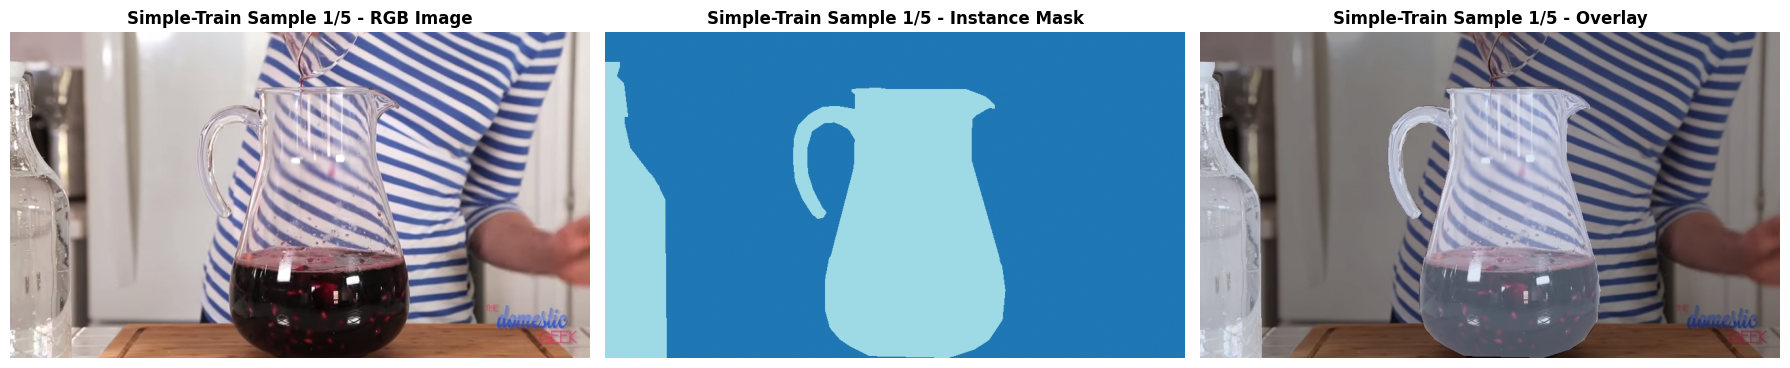


Simple-Train Sample 2/5
Image: 6 Classic Cocktail Recipes!-screenshot
Number of instances: 1

Material Categories by Instance ID:
  Instance 1: Liquid GENERAL
  Instance 2: Foam

Multi-phase material instances: [1, 2]
Multi-phase vessel instances: [1]


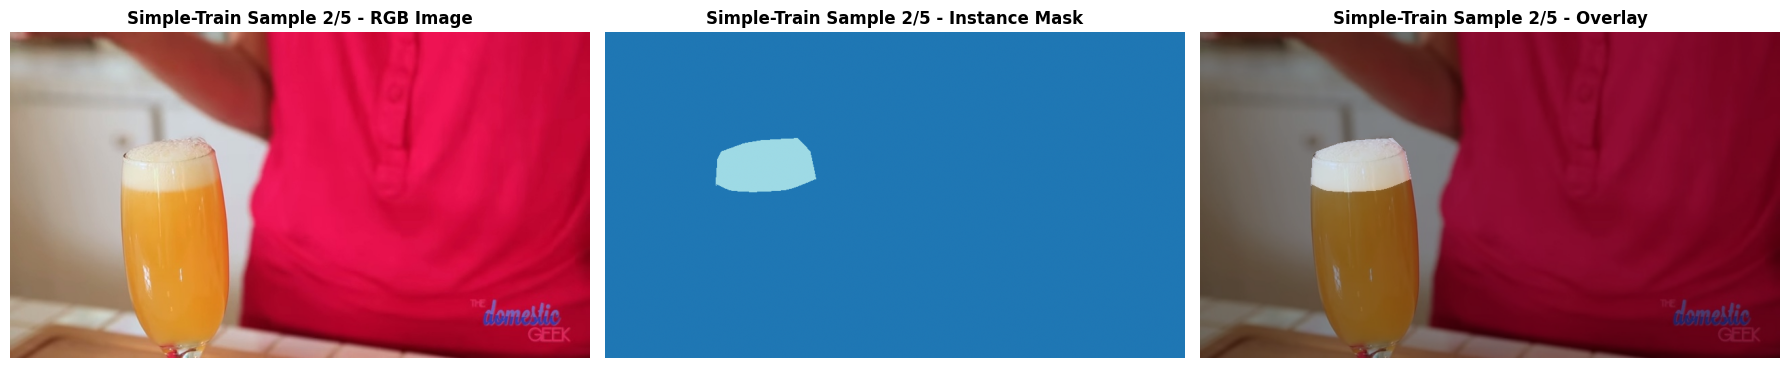


Simple-Train Sample 3/5
Image: 6 Classic Cocktail Recipes!-screenshot (1)
Number of instances: 1

Material Categories by Instance ID:
  Instance 1: Liquid GENERAL
  Instance 2: Liquid GENERAL


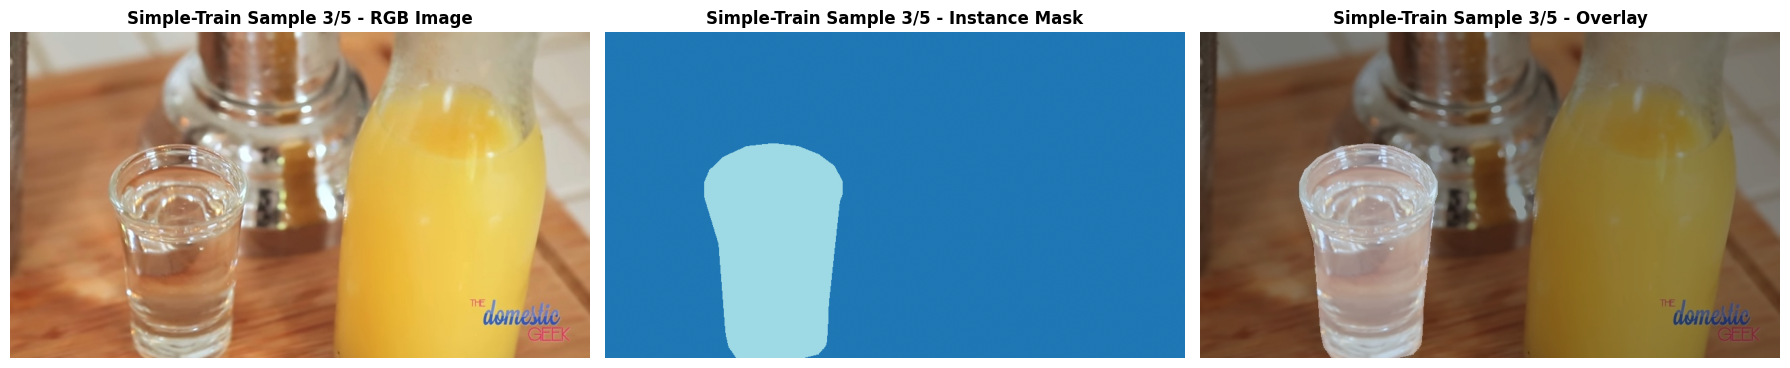


Simple-Train Sample 4/5
Image: 6 Classic Cocktail Recipes!-screenshot (2)
Number of instances: 1

Material Categories by Instance ID:
  Instance 1: Liquid GENERAL
  Instance 2: Liquid GENERAL


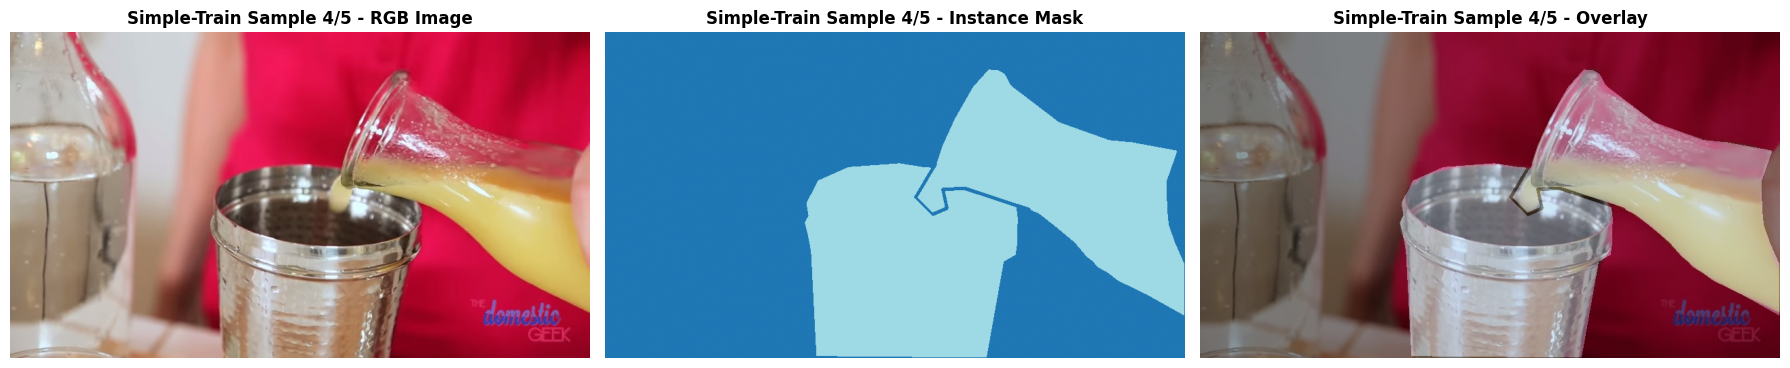


Simple-Train Sample 5/5
Image: A Gas Phase Reaction- Producing Ammonium Chloride-screenshot
Number of instances: 1

Material Categories by Instance ID:
  Instance 1: Liquid GENERAL
  Instance 2: Liquid GENERAL


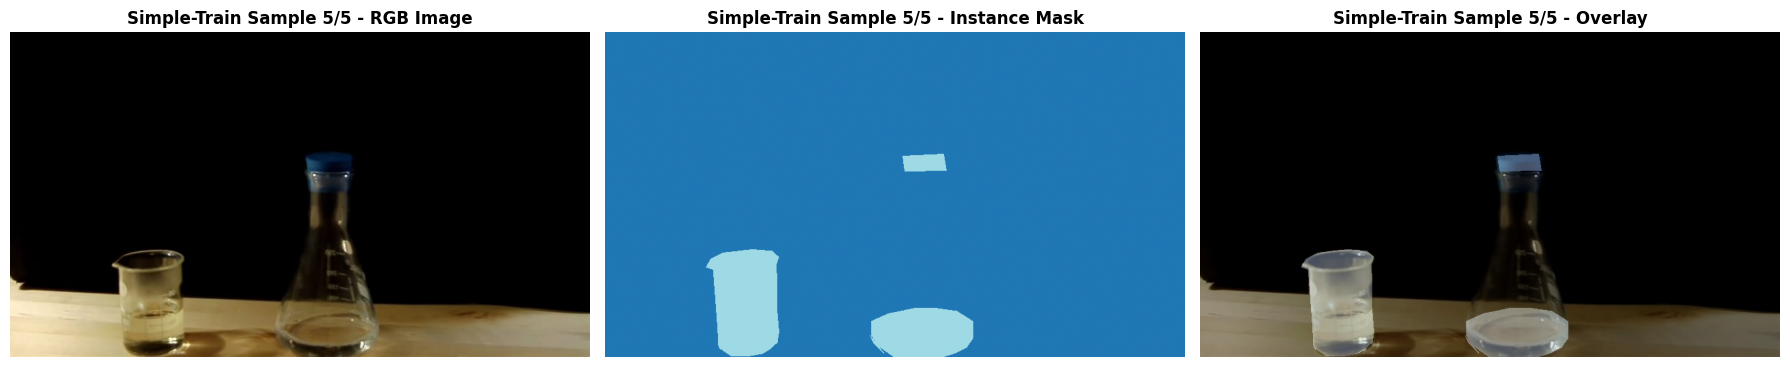

In [18]:
simple_train_annotations = load_annotation(simple_train_root)
simple_train_images = get_image_names(simple_train_root, limit=5)
print(f"Visualizing {len(simple_train_images)} samples from Simple-Train split...")
for i, img_name in enumerate(simple_train_images, 1):
    visualize_sample(simple_train_root, img_name, simple_train_annotations, 
                     title_prefix=f"Simple-Train Sample {i}/{len(simple_train_images)}")

## Simple Difficulty - Test Samples

Visualizing 5 samples from Simple-Test split...

Simple-Test Sample 1/5
Image: Koen2All_Chemistry experiment 10 - Elephant's toothpaste-screenshot
Number of instances: 1

Material Categories by Instance ID:
  Instance 1: Liquid GENERAL
  Instance 2: Foam

Multi-phase material instances: [1, 2]
Multi-phase vessel instances: [2]


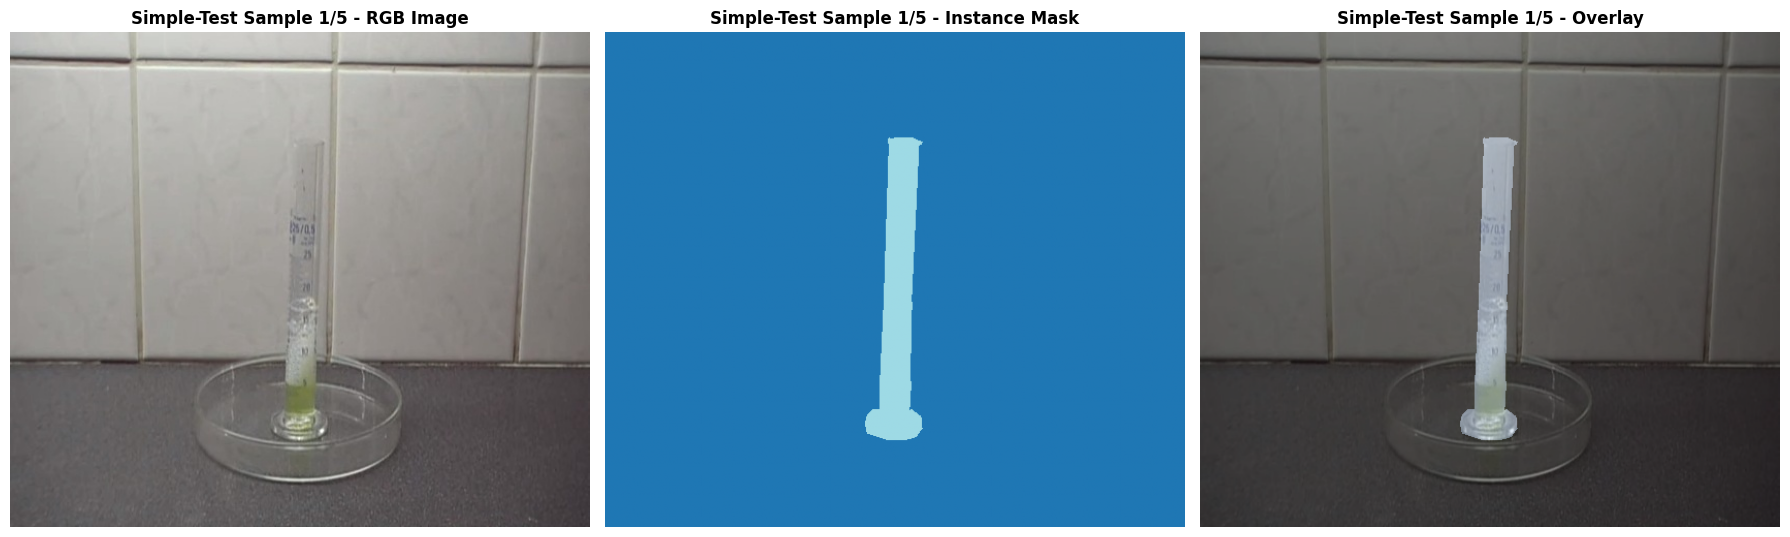


Simple-Test Sample 2/5
Image: Koen2All_Chemistry experiment 10 - Elephant's toothpaste-screenshot (1)
Number of instances: 1

Material Categories by Instance ID:
  Instance 1: Liquid GENERAL
  Instance 2: Liquid GENERAL
  Instance 3: Liquid Suspension, Solid GENERAL, Liquid GENERAL

Multi-phase material instances: [2, 3, 2, 3]
Multi-phase vessel instances: [1, 2]


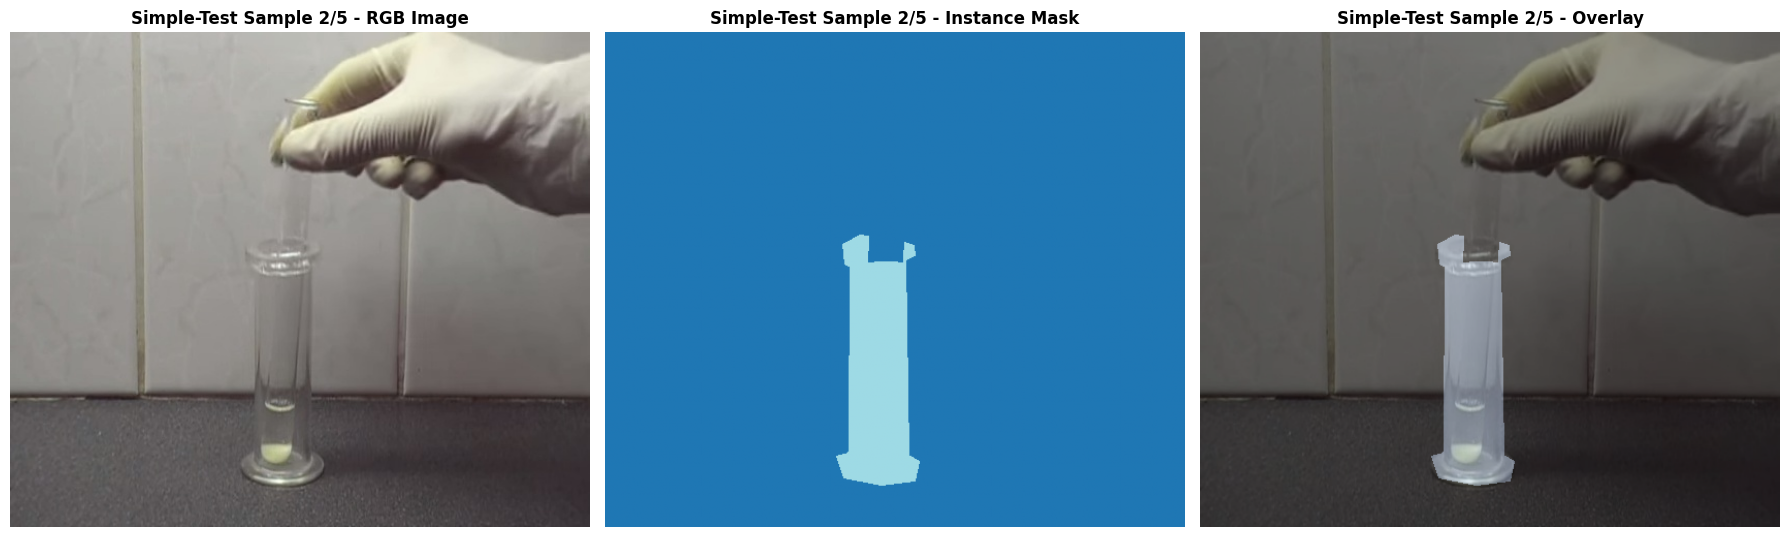


Simple-Test Sample 3/5
Image: Koen2All_Chemistry experiment 11 - Jumping sodium-screenshot
Number of instances: 0

Material Categories by Instance ID:
  Instance 1: Liquid GENERAL


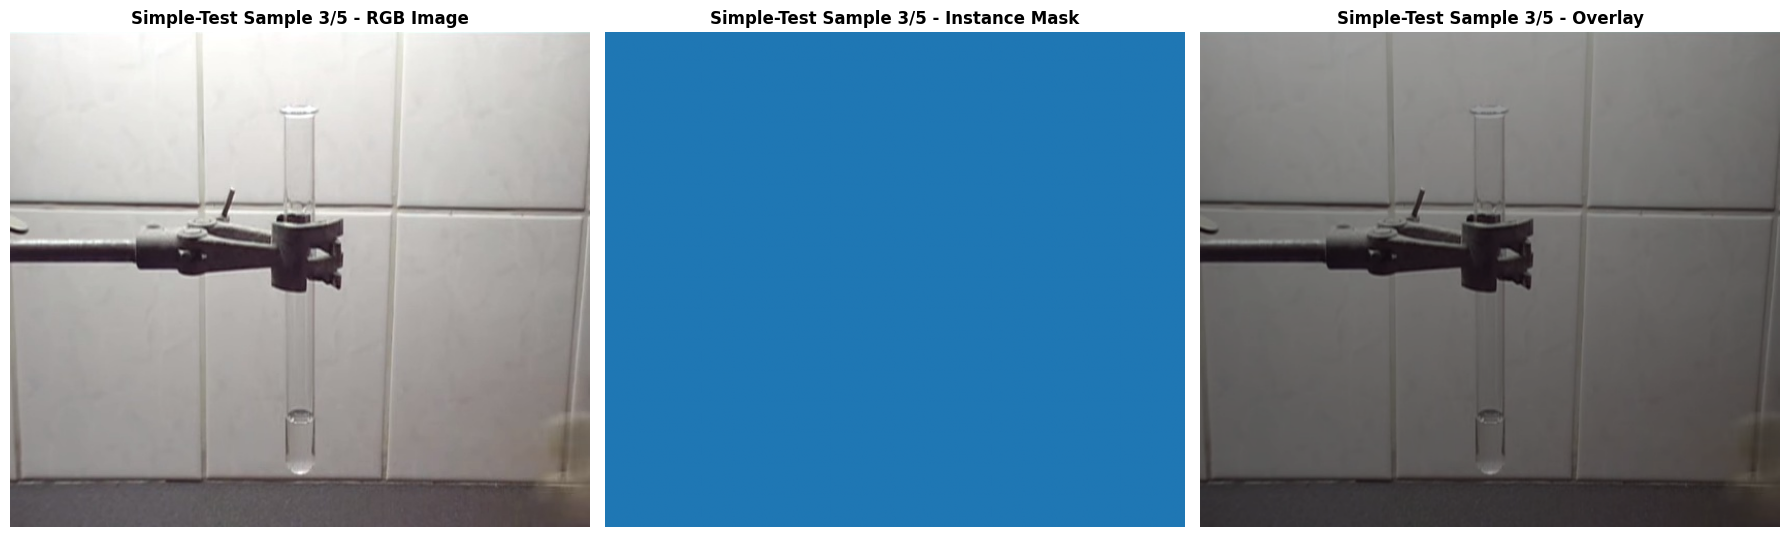


Simple-Test Sample 4/5
Image: Koen2All_Chemistry experiment 11 - Jumping sodium-screenshot (1)
Number of instances: 1

Material Categories by Instance ID:
  Instance 1: Liquid GENERAL
  Instance 2: Liquid GENERAL

Multi-phase material instances: [1, 2]
Multi-phase vessel instances: [1]


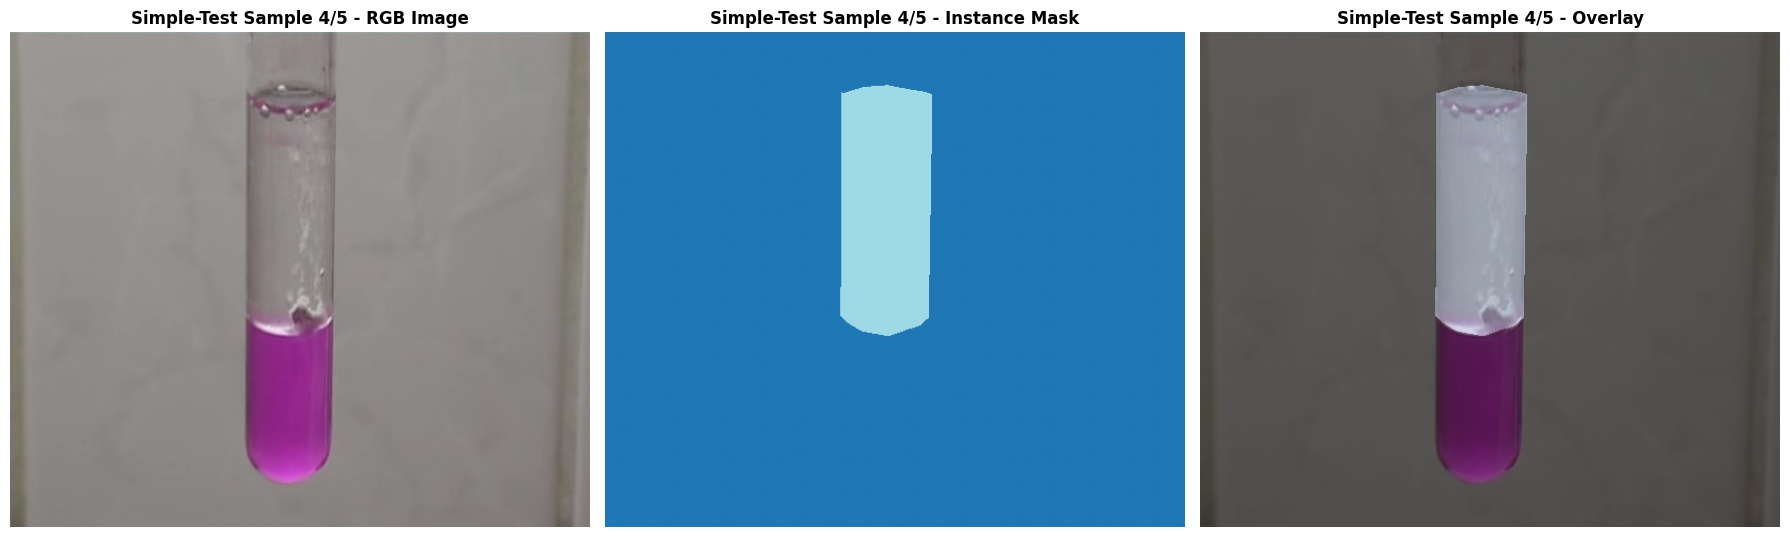


Simple-Test Sample 5/5
Image: Koen2All_Chemistry experiment 11 - Jumping sodium-screenshot (2)
Number of instances: 1

Material Categories by Instance ID:
  Instance 1: Liquid GENERAL
  Instance 2: Liquid GENERAL

Multi-phase material instances: [1, 2]
Multi-phase vessel instances: [1]


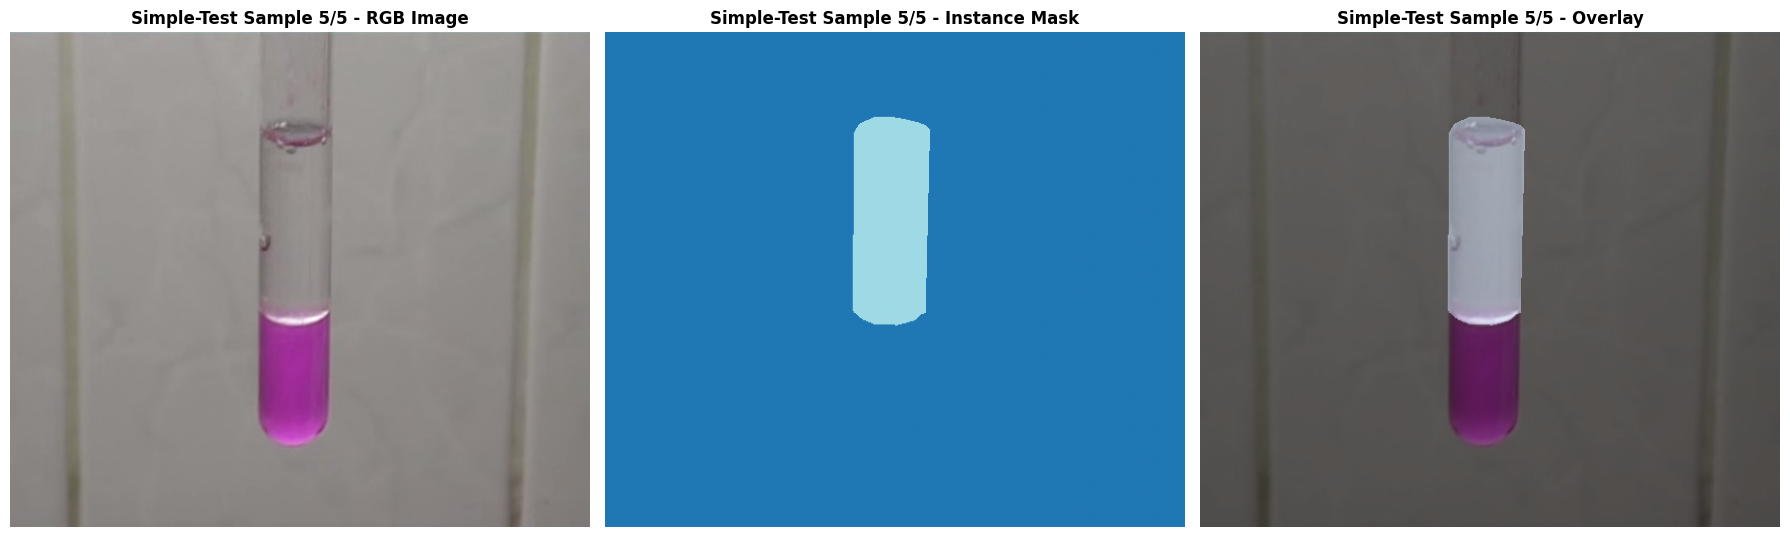

In [19]:
simple_test_annotations = load_annotation(simple_test_root)
simple_test_images = get_image_names(simple_test_root, limit=5)
print(f"Visualizing {len(simple_test_images)} samples from Simple-Test split...")
for i, img_name in enumerate(simple_test_images, 1):
    visualize_sample(simple_test_root, img_name, simple_test_annotations, 
                     title_prefix=f"Simple-Test Sample {i}/{len(simple_test_images)}")

## Complex Difficulty - Training Samples

In [20]:
complex_train_anno_file = complex_train_root / 'InstCategory.json'
if complex_train_anno_file.exists():
    complex_train_annotations = load_annotation(complex_train_root)
    complex_train_images = get_image_names(complex_train_root, limit=5)
    print(f"Visualizing {len(complex_train_images)} samples from Complex-Train split...")
    for i, img_name in enumerate(complex_train_images, 1):
        visualize_sample(complex_train_root, img_name, complex_train_annotations, 
                         title_prefix=f"Complex-Train Sample {i}/{len(complex_train_images)}")
else:
    print("Complex-Train annotation file not available. Skipping visualization.")

Complex-Train annotation file not available. Skipping visualization.


## Complex Difficulty - Test Samples

In [21]:
complex_test_anno_file = complex_test_root / 'InstCategory.json'
if complex_test_anno_file.exists():
    complex_test_annotations = load_annotation(complex_test_root)
    complex_test_images = get_image_names(complex_test_root, limit=5)
    print(f"Visualizing {len(complex_test_images)} samples from Complex-Test split...")
    for i, img_name in enumerate(complex_test_images, 1):
        visualize_sample(complex_test_root, img_name, complex_test_annotations, 
                         title_prefix=f"Complex-Test Sample {i}/{len(complex_test_images)}")
else:
    print("Complex-Test annotation file not available. Skipping visualization.")

Complex-Test annotation file not available. Skipping visualization.


## Semantic Segmentation Visualization

This section shows the semantic segmentation masks for various material categories.

Semantic Segmentation - Simple Difficulty Sample


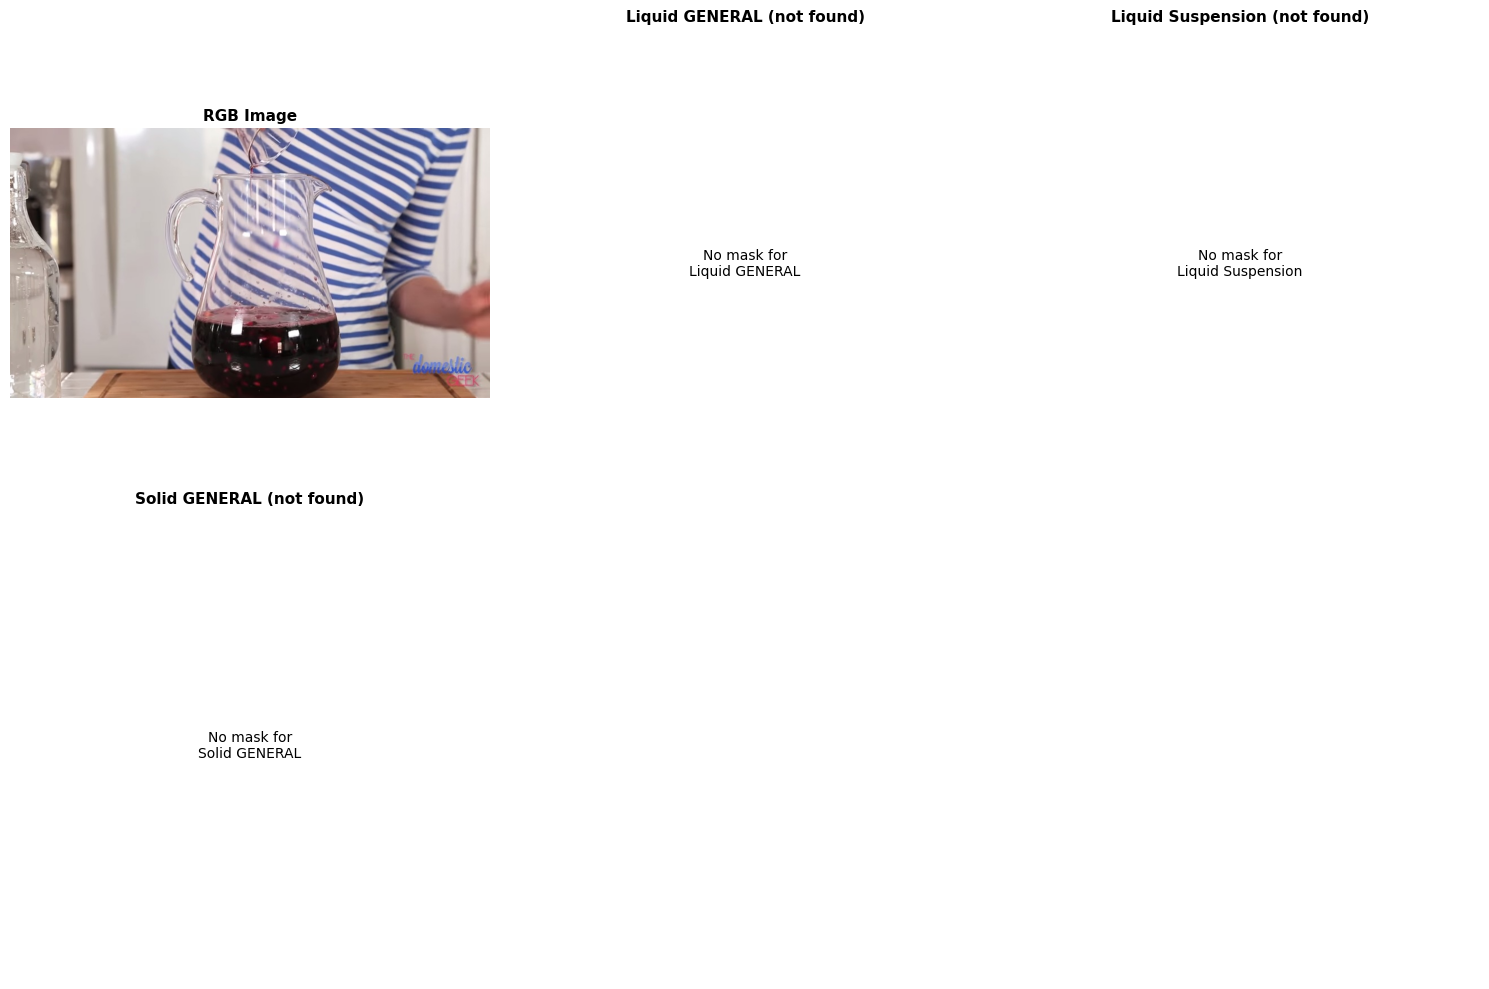


Complex difficulty semantic segmentation not available


In [22]:
def load_semantic_mask(root_path, image_name, material_name):
    """Load semantic segmentation mask for a specific material."""
    semantic_path = root_path / 'Semantic' / material_name / f'{image_name}.png'
    if semantic_path.exists():
        return np.array(Image.open(semantic_path))
    return None

def visualize_semantic_segmentation(root_path, image_name, annotations, max_materials=6):
    """Visualize semantic segmentation for all materials of a sample."""
    rgb_image = load_rgb_image(root_path, image_name)
    anno = annotations.get(image_name, {})
    
    # Get unique materials from material categories
    unique_materials = set()
    for materials in anno.get('MaterialCats', {}).values():
        unique_materials.update(materials)
    
    unique_materials = sorted(list(unique_materials))[:max_materials]
    
    # Create subplots (need space for RGB + all materials)
    num_materials = len(unique_materials)
    cols = 3
    rows = (num_materials + 1 + cols - 1) // cols  # Ceiling division for RGB + materials
    
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5*rows))
    axes = axes.flatten()
    
    # Show RGB image
    axes[0].imshow(rgb_image)
    axes[0].set_title('RGB Image', fontsize=11, fontweight='bold')
    axes[0].axis('off')
    
    # Show semantic masks
    for idx, material in enumerate(unique_materials, 1):
        semantic_mask = load_semantic_mask(root_path, image_name, material)
        
        if semantic_mask is not None:
            axes[idx].imshow(semantic_mask, cmap='gray')
            axes[idx].set_title(f'{material}', fontsize=11, fontweight='bold')
            pixels = np.count_nonzero(semantic_mask)
            axes[idx].text(0.5, -0.05, f'Pixels: {pixels}', 
                          transform=axes[idx].transAxes, ha='center', fontsize=9)
        else:
            axes[idx].text(0.5, 0.5, f'No mask for\n{material}', 
                          ha='center', va='center', fontsize=10)
            axes[idx].set_title(f'{material} (not found)', fontsize=11, fontweight='bold')
        
        axes[idx].axis('off')
    
    # Hide unused subplots
    for idx in range(idx + 1, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()

print("="*80)
print("Semantic Segmentation - Simple Difficulty Sample")
print("="*80)
if simple_train_images:
    visualize_semantic_segmentation(simple_train_root, simple_train_images[0], simple_train_annotations)

if complex_train_anno_file.exists() and complex_train_images:
    print("\n" + "="*80)
    print("Semantic Segmentation - Complex Difficulty Sample")
    print("="*80)
    visualize_semantic_segmentation(complex_train_root, complex_train_images[0], complex_train_annotations)
else:
    print("\nComplex difficulty semantic segmentation not available")

## Detailed Material Analysis

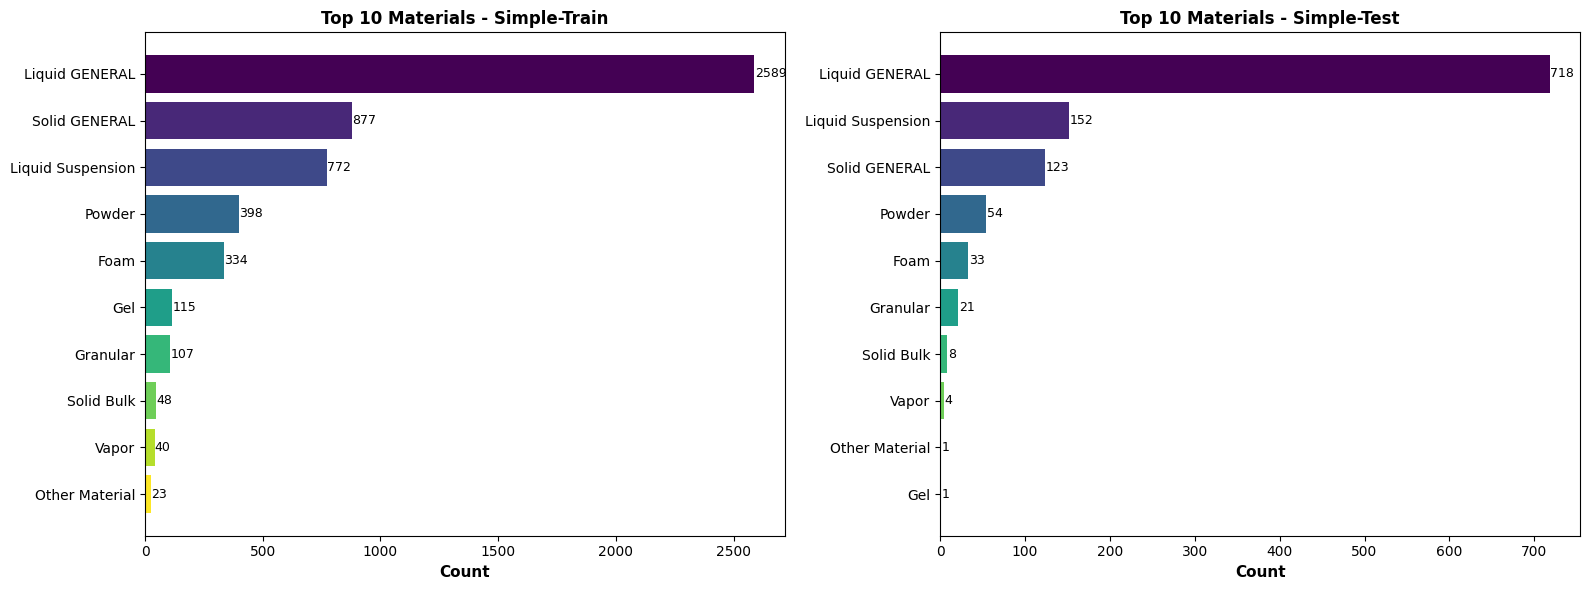


Material Distribution by Split

Simple-Train:
  Total instances: 5303
  Unique materials: 10
  Top 5 materials:
    - Liquid GENERAL: 2589 (48.8%)
    - Solid GENERAL: 877 (16.5%)
    - Liquid Suspension: 772 (14.6%)
    - Powder: 398 (7.5%)
    - Foam: 334 (6.3%)

Simple-Test:
  Total instances: 1115
  Unique materials: 10
  Top 5 materials:
    - Liquid GENERAL: 718 (64.4%)
    - Liquid Suspension: 152 (13.6%)
    - Solid GENERAL: 123 (11.0%)
    - Powder: 54 (4.8%)
    - Foam: 33 (3.0%)


In [23]:
def analyze_by_difficulty():
    """Analyze material distribution by difficulty level."""
    result = {}
    split_roots_local = {
        'Simple-Train': simple_train_root,
        'Simple-Test': simple_test_root,
        'Complex-Train': complex_train_root,
        'Complex-Test': complex_test_root,
    }
    
    for split_name, root in split_roots_local.items():
        anno_file = root / 'InstCategory.json'
        if anno_file.exists():
            annotations = load_annotation(root)
            material_counter = Counter()
            for anno in annotations.values():
                for materials in anno.get('MaterialCats', {}).values():
                    for mat in materials:
                        material_counter[mat] += 1
            result[split_name] = material_counter
    return result

material_by_difficulty = analyze_by_difficulty()
if material_by_difficulty:
    num_plots = len(material_by_difficulty)
    cols = 2
    rows = (num_plots + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(16, 6*rows))
    axes = axes.flatten()
    for ax_idx, (split_name, material_counter) in enumerate(material_by_difficulty.items()):
        ax = axes[ax_idx]
        materials, counts = zip(*material_counter.most_common(10))
        colors_list = plt.cm.viridis(np.linspace(0, 1, len(materials)))
        bars = ax.barh(range(len(materials)), counts, color=colors_list)
        ax.set_yticks(range(len(materials)))
        ax.set_yticklabels(materials, fontsize=10)
        ax.set_xlabel('Count', fontsize=11, fontweight='bold')
        ax.set_title(f'Top 10 Materials - {split_name}', fontsize=12, fontweight='bold')
        ax.invert_yaxis()
        for i, (mat, count) in enumerate(zip(materials, counts)):
            ax.text(count + 1, i, str(count), va='center', fontsize=9)
    for ax_idx in range(len(material_by_difficulty), len(axes)):
        axes[ax_idx].axis('off')
    plt.tight_layout()
    plt.show()
    print("\n" + "="*80)
    print("Material Distribution by Split")
    print("="*80)
    for split_name, material_counter in material_by_difficulty.items():
        total_instances = sum(material_counter.values())
        unique_materials = len(material_counter)
        print(f"\n{split_name}:")
        print(f"  Total instances: {total_instances}")
        print(f"  Unique materials: {unique_materials}")
        print(f"  Top 5 materials:")
        for material, count in material_counter.most_common(5):
            percentage = (count / total_instances) * 100
            print(f"    - {material}: {count} ({percentage:.1f}%)")
else:
    print("No material distribution data available.")